# With cap: 18:58–19:06 pooled recording

The three logger files beginning at **18:58:00**, **18:58:42**, and **19:00:07**
are treated as one analysis session ending at **19:06:47**. The file beginning at
19:06:47 is outside this interval. The plots match the with-cap notebook:
one eight-channel inspection figure, two channel-mean spectra, and four
independent 17/19 Hz CCA projection spectra. Both averaging orders use
**5-second epochs**, DPSS NW=1/K=1 and a 0.2 Hz FFT grid.

Recorded sample sequence numbers preserve the actual time axis. There are
three gaps; no missing EEG is invented or interpolated. Spectral epochs restart
at each uninterrupted span, so no FFT crosses a gap. A three-sample fragment
cannot resolve the target frequencies and is omitted only from spectra; it
remains in the whole-session CCA fit and the audit. Rolling 1-second CCA fits
stay inside uninterrupted spans and leave that short fragment unassigned.

Only **C9–C16 (chip 2)** were stored. The binary slots for C17–C24 (chip 3)
are zero, so chip 3 is not shown. No game or condition labels are inferred.
All signals are the recorded board-filtered microvolt values, with no extra
filtering, CAR, artifact rejection, phase alignment or interpolation. Whole-
session CCA uses the true sequence times in its sine/cosine references;
rolling CCA uses logged endpoints plus boundary fits. This is an offline
reconstruction with window look-ahead rather than a causal firmware replay.


In [1]:
from pathlib import Path
from functools import lru_cache
import base64, hashlib, html, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import HTML, display
ROOT = Path.cwd()
if not (ROOT / 'data/2026-11-02').is_dir():
    ROOT = Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis')
DATA_ROOT = ROOT / 'data/2026-11-02'
SESSION_ID = 'eeg_20261102_185800_to_190647'
SESSION_LABEL = '250sps 10Hz NF with cap; pooled 18:58–19:06'
SOURCE_IDS = ('eeg_20261102_185800', 'eeg_20261102_185842', 'eeg_20261102_190007')
SOURCE_FOLDERS = {sid: f'{sid}_cap-10hzProc' for sid in SOURCE_IDS}
FS, TARGETS_HZ = 250.0, (17.0, 19.0)
EPOCH_SECONDS = 5.0
EPOCH_SAMPLES = int(round(FS * EPOCH_SECONDS))
WINDOW_SAMPLES, HOP_SAMPLES = 250, 25
MIN_SPECTRAL_SAMPLES = WINDOW_SAMPLES
RECORDED_CHANNEL_NAMES = [f'C{i}' for i in range(9, 17)]
RECORDED_CHANNEL_COLUMNS = [f'ch{i}_uv' for i in range(9, 17)]
CHANNEL_PSD_FREQ_LIMITS, FREQ_LIMITS = (5., 40.), (5., 30.)
PLOT_EXPORT_DPI = 200
EXPORT_ROOT = ROOT / 'plots' / f'2026-11-02_with_cap_1858-1906_{EPOCH_SECONDS:g}s'
EXPORT_ROOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.18, 'font.size':10})
assert EPOCH_SAMPLES >= 2

## Decode and audit the three source files

The binary record format is `uint32 seq`, 32 packed float32 channel slots, and
`uint16 marker`. The first eight slots map to C9–C16. Each source is read
separately and then concatenated in sequence order. Metadata and actual file
record counts are both reported, including any mismatch. Gaps and file
boundaries are audited explicitly.


In [2]:
SIGNAL_DTYPE = np.dtype([('seq','<u4'), ('values','<f4',(32,)), ('marker','<u2')])
FEATURE_DTYPE = np.dtype([('is_cca','u1'), ('reserved','u1'), ('marker','<u2'),
    ('seq','<u4'), ('values','<f4',(26,))])
assert SIGNAL_DTYPE.itemsize == 134 and FEATURE_DTYPE.itemsize == 112

source_rows, input_hashes, seq_parts, eeg_parts, logged_parts = [], [], [], [], []
for sid in SOURCE_IDS:
    folder = DATA_ROOT / SOURCE_FOLDERS[sid]
    meta = json.loads((folder / f'{sid}_meta.json').read_text(encoding='utf-8-sig'))
    if meta['fs'] != FS or meta['num_ch'] != 8 or meta['ch_map'] != list(range(8,16)):
        raise ValueError(f'{sid}: unexpected sample rate or channel map')
    path = folder / f'{sid}_signals.bin'
    if path.stat().st_size % SIGNAL_DTYPE.itemsize:
        raise ValueError(f'{sid}: incomplete binary record')
    samples = np.fromfile(path, dtype=SIGNAL_DTYPE)
    features = np.fromfile(folder / f'{sid}_features.bin', dtype=FEATURE_DTYPE)
    seq = samples['seq'].astype(np.int64)
    eeg = samples['values'][:, :8].astype(float)
    if not len(seq) or not np.isfinite(eeg).all() or np.any(np.diff(seq) <= 0):
        raise ValueError(f'{sid}: nonfinite EEG or nonincreasing sequence')
    if np.any(samples['values'][:, 8:]) or np.any(samples['marker']):
        raise ValueError(f'{sid}: unexpected chip-3 data or markers; inspect manually')
    if len(features) != meta['features_samples']:
        raise ValueError(f'{sid}: feature-file count differs from metadata')
    seq_parts.append(seq)
    eeg_parts.append(eeg)
    logged_parts.append(features['seq'][features['is_cca'] == 1].astype(np.int64))
    source_rows.append(dict(file=sid, start_time=meta['start_time'], end_time=meta['end_time'],
        metadata_samples=meta['signals_samples'], file_samples=len(samples),
        count_difference=len(samples)-meta['signals_samples'], first_seq=int(seq[0]),
        last_seq=int(seq[-1]), internal_gap_events=int(np.count_nonzero(np.diff(seq)!=1))))
    for source_file in sorted(folder.iterdir()):
        if source_file.is_file():
            input_hashes.append(dict(file=source_file.name, folder=folder.name,
                bytes=source_file.stat().st_size,
                sha256=hashlib.sha256(source_file.read_bytes()).hexdigest()))

seq = np.concatenate(seq_parts)
x = np.concatenate(eeg_parts)
if np.any(np.diff(seq) <= 0):
    raise ValueError('Source files overlap or are out of sequence order')
breaks = np.flatnonzero(np.diff(seq) != 1)
segment_edges = np.r_[0, breaks+1, len(seq)]
segments = [(int(a), int(b)) for a,b in zip(segment_edges[:-1], segment_edges[1:])]
gap_audit = pd.DataFrame([dict(after_seq=int(seq[i]), before_seq=int(seq[i+1]),
    missing_samples=int(seq[i+1]-seq[i]-1), missing_seconds=(seq[i+1]-seq[i]-1)/FS)
    for i in breaks])
source_audit = pd.DataFrame(source_rows)
records = [dict(session=SESSION_ID, label=SESSION_LABEL,
    display_name='18:58–19:06 | 250sps 10Hz NF with cap',
    source='board-filtered; pooled files',
    seq=seq, recorded_x=x, nfseq=np.unique(np.concatenate(logged_parts)), segments=segments)]
source_audit.to_csv(EXPORT_ROOT / 'source_audit.csv', index=False)
gap_audit.to_csv(EXPORT_ROOT / 'gap_audit.csv', index=False)
pd.DataFrame(input_hashes).to_csv(EXPORT_ROOT / 'input_sha256.csv', index=False)
display(source_audit)
display(gap_audit)
print(f'One pooled session: {len(seq)} observed samples, {seq[-1]-seq[0]+1} sequence positions, '
      f'{len(breaks)} gaps, {gap_audit.missing_samples.sum()} missing samples; '
      f'{len(segments)} uninterrupted spans.')

,file,start_time,end_time,metadata_samples,file_samples,count_difference,first_seq,last_seq,internal_gap_events
0,eeg_20261102_185800,2026-11-02 18:58:00,2026-11-02 18:58:42,4298,4296,-2,85274,95730,1
1,eeg_20261102_185842,2026-11-02 18:58:42,2026-11-02 19:00:07,20767,20767,0,95733,116988,1
2,eeg_20261102_190007,2026-11-02 19:00:07,2026-11-02 19:06:47,99154,99154,0,116989,216142,0


,after_seq,before_seq,missing_samples,missing_seconds
0,89566,95728,6161,24.644
1,95730,95733,2,0.008
2,116498,116988,489,1.956


One pooled session: 124217 observed samples, 130869 sequence positions, 3 gaps, 6652 missing samples; 4 uninterrupted spans.


## Spectral estimator

Each uninterrupted span is divided into consecutive 5-second epochs. A trailing
partial epoch is NaN padded only at its end. The isolated three-sample span is
too short to estimate a 17/19 Hz spectrum and is audited but omitted from PSDs.
All other observed samples enter the spectra. DPSS NW=1/K=1 is applied to each
observed epoch before zero padding to the shared FFT grid. Both averaging
orders pool eligible epochs equally across the whole recording.


In [3]:
"""NaN-aware spectra for the configured epoch duration."""
import numpy as np
from scipy import signal

def epoch_trials(waveforms, epoch_samples):
    """Trial x epoch x sample [x projection]; retain every observed sample."""
    waves = [np.asarray(w, float) for w in waveforms]
    if not waves or epoch_samples < 2 or any(not np.isfinite(w).all() for w in waves):
        raise ValueError('Need nonempty, finite observed trials and a valid epoch length')
    tail_shape = waves[0].shape[1:]
    if any(w.shape[1:] != tail_shape for w in waves):
        raise ValueError('Projection shapes differ between trials')
    count = max((len(w)+epoch_samples-1)//epoch_samples for w in waves)
    result = np.full((len(waves), count, epoch_samples, *tail_shape), np.nan)
    for j, wave in enumerate(waves):
        for k, start in enumerate(range(0, len(wave), epoch_samples)):
            block = wave[start:start+epoch_samples]
            result[j, k, :len(block)] = block
    return result

def nan_epoch_psd(epoch, fs, epoch_samples):
    """Missing tails never enter detrending/tapering; common configured-length FFT grid."""
    x = np.asarray(epoch, float)
    valid = np.isfinite(x if x.ndim == 1 else x[:, 0])
    length = int(valid.sum())
    if not np.array_equal(valid, np.arange(len(x)) < length):
        raise ValueError('Only trailing NaNs are supported')
    f = np.fft.rfftfreq(epoch_samples, d=1/fs)
    if length < 2:
        return f, np.full((len(f), *x.shape[1:]), np.nan)
    observed = x[:length]
    if not np.isfinite(observed).all():
        raise ValueError('Inconsistent missing data across projections')
    # A 2-sample final fragment cannot support NW=1; use the largest legal NW.
    taper = signal.windows.dpss(length, NW=min(1., (length-1)/2), Kmax=1, sym=False)[0]
    return signal.periodogram(observed, fs=fs, window=taper, nfft=epoch_samples,
                              detrend='constant', scaling='density', axis=0)

def finite_mean(values, axis=0):
    values = np.asarray(values, float)
    count = np.isfinite(values).sum(axis=axis)
    total = np.nansum(values, axis=axis)
    return np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)

def pooled_trial_spectrum_orders(padded, fs):
    """Two epoch orders, with equal trial weighting in both operations."""
    n = padded.shape[2]
    epoch_power = np.stack([np.stack([nan_epoch_psd(e, fs, n)[1] for e in trial]) for trial in padded])
    # First average a trial's observed epoch spectra; then average trials equally.
    trial_power = finite_mean(epoch_power, axis=1)
    power_first = finite_mean(trial_power, axis=0)
    # First form each trial's NaN-aware mean epoch; then average those trials.
    trial_mean_epochs = finite_mean(padded, axis=1)
    mean_epoch = finite_mean(trial_mean_epochs, axis=0)
    f, waveform_first = nan_epoch_psd(mean_epoch, fs, n)
    counts = np.isfinite(trial_mean_epochs[..., 0] if trial_mean_epochs.ndim == 3 else trial_mean_epochs).sum(axis=0)
    return dict(f=f, induced=power_first, evoked=waveform_first, mean_epoch=mean_epoch,
                counts=counts, trial_power=trial_power, epoch_power=epoch_power)

def pooled_gap_spectrum_orders(wave, segments):
    """Epoch each contiguous span and average eligible epochs across the pooled run."""
    wave = np.asarray(wave, float)
    padded, info = [], []
    for span_number,(a,b) in enumerate(segments,1):
        for start in range(a,b,EPOCH_SAMPLES):
            block = wave[start:min(start+EPOCH_SAMPLES,b)]
            eligible = len(block) >= MIN_SPECTRAL_SAMPLES and np.isfinite(block).all()
            info.append(dict(span=span_number, first_index=start, observed_samples=len(block),
                complete=len(block)==EPOCH_SAMPLES, spectral_eligible=bool(eligible)))
            if eligible:
                epoch = np.full((EPOCH_SAMPLES,*wave.shape[1:]),np.nan)
                epoch[:len(block)] = block
                padded.append(epoch)
    if not padded:
        raise ValueError('No uninterrupted epochs long enough for a spectrum')
    padded = np.stack(padded)
    power = np.stack([nan_epoch_psd(epoch,FS,EPOCH_SAMPLES)[1] for epoch in padded])
    mean_epoch = finite_mean(padded,axis=0)
    f, evoked = nan_epoch_psd(mean_epoch,FS,EPOCH_SAMPLES)
    return dict(f=f,induced=finite_mean(power,axis=0),evoked=evoked,
        padded=padded,mean_epoch=mean_epoch,epoch_power=power,
        complete=sum(row['complete'] and row['spectral_eligible'] for row in info),
        partial=sum(not row['complete'] and row['spectral_eligible'] for row in info),
        epochs=len(padded), observed_samples=sum(row['observed_samples'] for row in info if row['spectral_eligible']),
        omitted_samples=sum(row['observed_samples'] for row in info if not row['spectral_eligible']),
        epoch_info=info)

## Inspect all eight channels separately

One 2 x 4 grid per session, 5-40 Hz. Dotted 17/19 Hz lines are inherited analysis targets.
Flat channels are labelled without an artificial dB floor. Full 0-125 Hz numeric spectra
and channel variability diagnostics are exported.


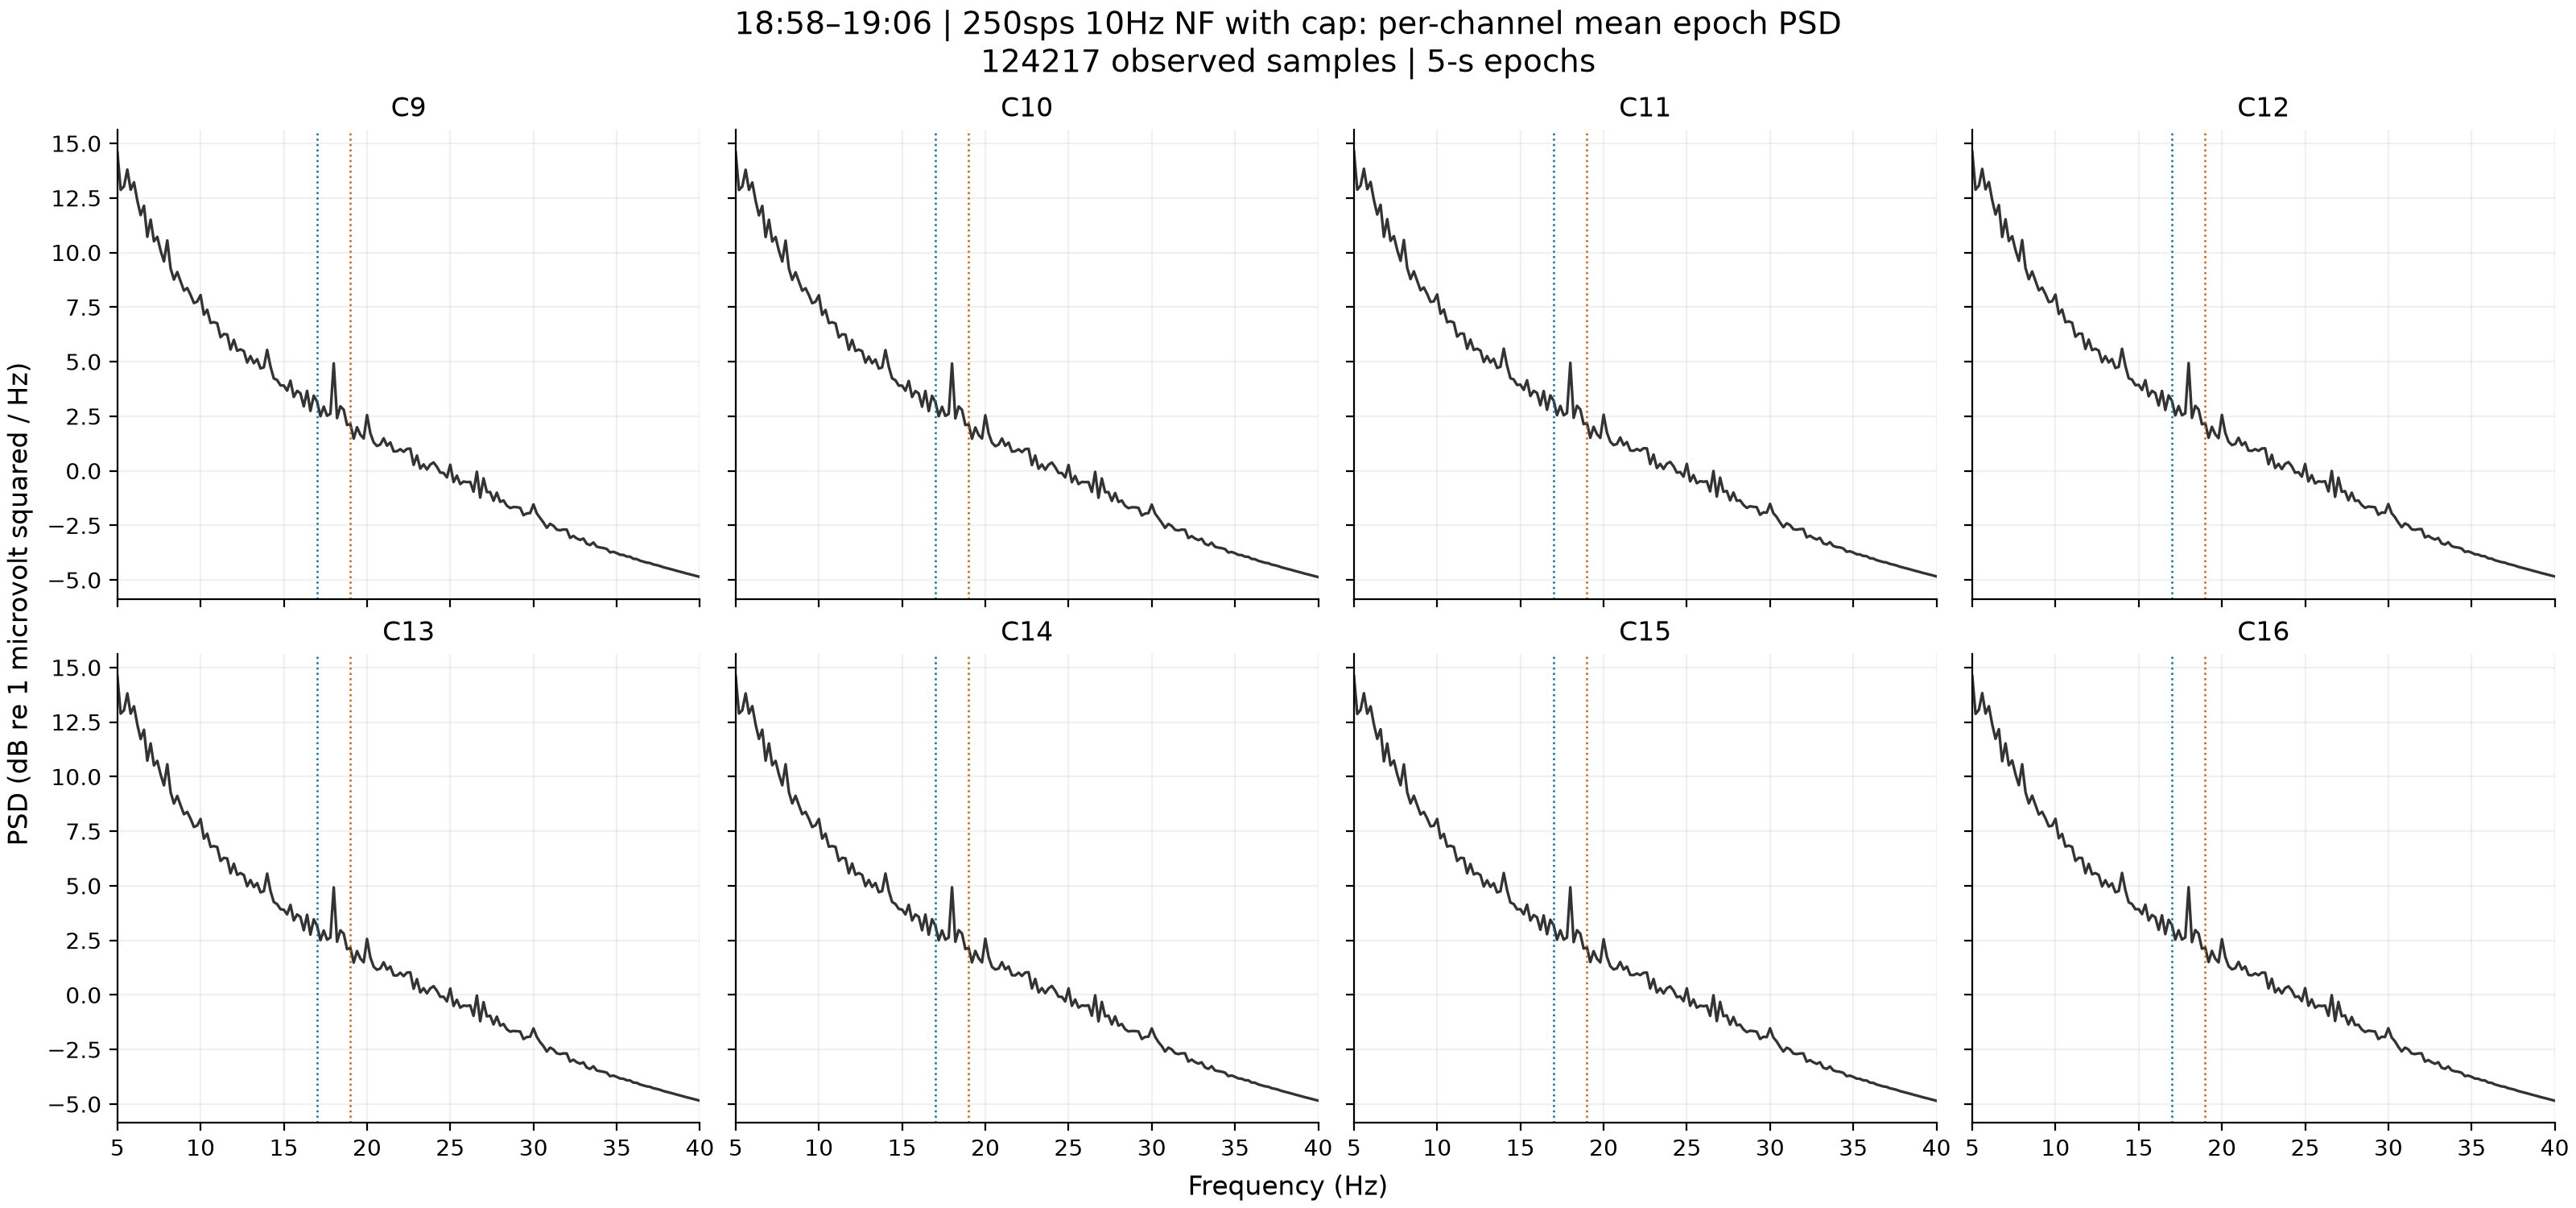

In [4]:
def db_plot(power):
    power = np.asarray(power, float)
    return 10*np.log10(np.where(power>0, power, np.nan))
def limits_for(powers):
    values = np.concatenate([db_plot(p).ravel() for p in powers])
    values = values[np.isfinite(values)]
    if not len(values): return (-1,1)
    lo, hi = values.min(), values.max()
    pad = max((hi-lo)*.05,1.)
    return lo-pad, hi+pad

plot_exports = []
def save_figure(fig, rec, stem, title, caption, view, method, order, folder):
    folder.mkdir(parents=True, exist_ok=True)
    png, svg = folder / f'{stem}.png', folder / f'{stem}.svg'
    fig.savefig(png, dpi=PLOT_EXPORT_DPI)
    fig.savefig(svg)
    plt.close(fig)
    plot_exports.append(dict(session=rec['session'], label=rec['label'], source=rec['source'], view=view,
        method=method, order=order, title=title, caption=caption,
        selected_channels=', '.join(CHANNEL_NAMES) if view!='per_channel' else ', '.join(RECORDED_CHANNEL_NAMES),
        png=png.relative_to(EXPORT_ROOT).as_posix(), svg=svg.relative_to(EXPORT_ROOT).as_posix()))
    encoded = base64.b64encode(png.read_bytes()).decode('ascii')
    return (f'<img src="data:image/png;base64,{encoded}" style="width:100%;height:auto" alt="{html.escape(title)}">'
        f'<p>{html.escape(caption)}</p><a href="{png.relative_to(ROOT).as_posix()}">PNG</a> | '
        f'<a href="{svg.relative_to(ROOT).as_posix()}">SVG</a>')

variability_rows, per_channel_numeric = [], []
rec = records[0]
x = rec['recorded_x']
rec['channel_summary'] = pooled_gap_spectrum_orders(x, rec['segments'])
summary = rec['channel_summary']
f, power = summary['f'], summary['induced']
mask = (f >= CHANNEL_PSD_FREQ_LIMITS[0]) & (f <= CHANNEL_PSD_FREQ_LIMITS[1])
fig, axes = plt.subplots(2,4,figsize=(16,7.5),sharex=True,sharey=True,constrained_layout=True)
ylim = limits_for([power[mask]])
for j,(channel,ax) in enumerate(zip(RECORDED_CHANNEL_NAMES,axes.flat)):
    variability_rows.append(dict(session=rec['session'], channel=channel,
        samples=len(x), std_uv=float(np.std(x[:,j])), peak_to_peak_uv=float(np.ptp(x[:,j]))))
    ax.plot(f[mask],db_plot(power[mask,j]),color='#333333',lw=1.2)
    for hz,color in zip(TARGETS_HZ,('#0072B2','#D55E00')):
        ax.axvline(hz,color=color,ls=':',lw=.9)
    ax.set(title=channel,xlim=CHANNEL_PSD_FREQ_LIMITS,ylim=ylim)
    per_channel_numeric.append(pd.DataFrame(dict(session=rec['session'],
        channel=channel,frequency_hz=f,power_uv2_per_hz=power[:,j])))
title = f'{rec["display_name"]}: per-channel mean epoch PSD'
fig.suptitle(f'{title}\n{len(x)} observed samples | {EPOCH_SECONDS:g}-s epochs',fontsize=14)
fig.supxlabel('Frequency (Hz)')
fig.supylabel('PSD (dB re 1 microvolt squared / Hz)')
caption = (f'Three files pooled as one analysis session. {len(breaks)} sequence gaps; '
    f'{summary["omitted_samples"]} short-fragment samples omitted from PSD only. '
    f'{summary["complete"]} complete + {summary["partial"]} partial epochs. '
    f'DPSS NW=1/K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid. '
    'Dotted blue/orange: 17/19 Hz analysis targets.')
panel = save_figure(fig,rec,'per_channel_mean_epoch_psd',title,caption,'per_channel',
    'independent_channels','spectrum_first',EXPORT_ROOT / rec['session'])
display(HTML(f'<h3>{html.escape(rec["session"])} — {html.escape(rec["label"])}</h3>{panel}'))
pd.DataFrame(variability_rows).to_csv(EXPORT_ROOT / 'per_channel_variability_audit.csv',index=False)
pd.concat(per_channel_numeric,ignore_index=True).to_csv(EXPORT_ROOT / 'per_channel_average_spectra.csv',index=False)

## Select channels for means and CCA

Edit the list and rerun this cell and everything below it. Inspection grids retain all channels.
Each selection has a separate results subfolder per session. C16 anchors CCA polarity when
selected; otherwise the largest absolute coefficient anchors polarity, as in the reference.

In [5]:
SELECTED_CHANNELS = ['C9','C10','C11','C12','C13','C14','C15','C16']
if (not isinstance(SELECTED_CHANNELS,(list,tuple)) or not SELECTED_CHANNELS or
        not all(isinstance(c,str) and c in RECORDED_CHANNEL_NAMES for c in SELECTED_CHANNELS) or
        len(set(SELECTED_CHANNELS))!=len(SELECTED_CHANNELS)):
    raise ValueError('Use a nonempty list of unique channel names from C9-C16')
CHANNEL_NAMES = list(SELECTED_CHANNELS)
SELECTED_CHANNEL_INDICES = [RECORDED_CHANNEL_NAMES.index(c) for c in CHANNEL_NAMES]
CHANNEL_COLUMNS = [RECORDED_CHANNEL_COLUMNS[i] for i in SELECTED_CHANNEL_INDICES]
SIGN_ANCHOR_INDEX = CHANNEL_NAMES.index('C16') if 'C16' in CHANNEL_NAMES else None
CHANNEL_LIST_TEXT = ', '.join(CHANNEL_NAMES)
SELECTION_TAG = 'channels_' + '_'.join(c[1:] for c in CHANNEL_NAMES)
for rec in records:
    rec['x'] = np.ascontiguousarray(rec['recorded_x'][:,SELECTED_CHANNEL_INDICES])
    rec['export_dir'] = EXPORT_ROOT / rec['session'] / SELECTION_TAG
    rec['export_dir'].mkdir(parents=True,exist_ok=True)
    selection = dict(session=rec['session'],label=rec['label'],selected_channels=CHANNEL_NAMES,
        recorded_channels=RECORDED_CHANNEL_NAMES,sample_rate_hz=FS,epoch_seconds=EPOCH_SECONDS,
        source=rec['source'],raw_preprocessing='recorded board-filtered microvolt signals; no offline filter',
        polarity_anchor='C16' if SIGN_ANCHOR_INDEX is not None else 'largest absolute coefficient')
    (rec['export_dir'] / 'selected_channels.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
plot_exports = [p for p in plot_exports if p['view']=='per_channel']
print('Downstream channels:',CHANNEL_LIST_TEXT)

Downstream channels: C9, C10, C11, C12, C13, C14, C15, C16


## Independent 17 Hz and 19 Hz CCA projections

The following CCA implementation and recovery/rank checks come from the reference notebook.
Direct data SVD avoids squaring the condition number. Each target has exactly two sine/cosine
columns and independent unit-norm EEG weights. Rolling fits use complete 1-second windows;
only newly covered samples are assigned. Fit means, weights, bounds, correlations and
endpoint provenance are saved. The raw session remains unfiltered for both CCA methods.

In [6]:
def reference_matrix(time_seconds, frequencies_hz):
    t = np.asarray(time_seconds, dtype=float)
    return np.column_stack([func(2*np.pi*f*t)
                            for f in frequencies_hz for func in (np.sin, np.cos)])

def joint_reference(time_seconds):
    return reference_matrix(time_seconds, TARGETS_HZ)

def whitening_basis(centered):
    # Direct data SVD avoids squaring the condition number through X.T @ X.
    q, singular_values, rotation = np.linalg.svd(centered, full_matrices=False)
    tolerance = max(centered.shape) * np.finfo(float).eps * singular_values[0]
    keep = singular_values > tolerance
    if not np.any(keep):
        raise ValueError('No nonzero variance for CCA')
    return rotation[keep].T / singular_values[keep], q[:, keep]

def fit_cca_projection(eeg_uv, time_seconds, frequencies_hz):
    x, y = np.asarray(eeg_uv, float), reference_matrix(time_seconds, frequencies_hz)
    if x.ndim != 2 or x.shape[0] != y.shape[0] or x.shape[1] != len(CHANNEL_COLUMNS):
        raise ValueError('Expected samples x selected channels and matching reference times')
    if len(x) <= x.shape[1]+y.shape[1] or not np.isfinite(x).all():
        raise ValueError('Insufficient samples or non-finite EEG')
    x_mean, y_mean = x.mean(axis=0), y.mean(axis=0)
    xc, yc = x-x_mean, y-y_mean
    (bx, qx), (by, qy) = whitening_basis(xc), whitening_basis(yc)
    left, strengths, right = np.linalg.svd(qx.T @ qy, full_matrices=False)
    w, v = bx @ left[:, 0], by @ right[0]
    w /= np.linalg.norm(w)
    v /= np.linalg.norm(v)
    anchor = SIGN_ANCHOR_INDEX
    fallback = anchor is None or abs(w[anchor]) <= 1e-12
    if fallback:
        anchor = int(np.argmax(np.abs(w)))
    if w[anchor] < 0:
        w, v = -w, -v
    u = xc @ w
    rho = float(np.corrcoef(u, yc @ v)[0, 1])
    if not np.isfinite(rho):
        raise ValueError('Degenerate projected variance')
    return dict(w=w, v=v, x_mean=x_mean, y_mean=y_mean, u=u, rho=rho,
                rho_svd=float(np.clip(strengths[0], 0, 1)), x_rank=bx.shape[1],
                y_rank=by.shape[1], sign_fallback=fallback,
                frequencies_hz=tuple(frequencies_hz), reference_columns=y.shape[1])

def fit_joint_cca(eeg_uv, time_seconds):
    return fit_cca_projection(eeg_uv, time_seconds, TARGETS_HZ)

def fit_target_cca(eeg_uv, time_seconds, target_hz):
    # Exactly two reference columns; each call estimates its own EEG weights.
    return fit_cca_projection(eeg_uv, time_seconds, (float(target_hz),))

@lru_cache(maxsize=None)
def dpss_taper(n_samples):
    return signal.windows.dpss(n_samples, NW=1, Kmax=1, sym=False)[0]

def psd(data, nfft=None):
    x = np.asarray(data, float)
    return signal.periodogram(x, fs=FS, window=dpss_taper(len(x)), nfft=len(x) if nfft is None else nfft,
        detrend='constant', return_onesided=True, scaling='density', axis=0)

def db(power):
    return 10*np.log10(np.maximum(np.asarray(power), np.finfo(float).tiny))

# Known linear mixture, rank deficiency, scaling, and phase-cancellation checks.
rng = np.random.default_rng(17)
t_test = np.arange(1000)/FS
r_test = joint_reference(t_test)
x_test = r_test @ rng.normal(size=(4, len(CHANNEL_COLUMNS)))
x_test += rng.normal(scale=.01, size=x_test.shape)
fit_test = fit_joint_cca(x_test, t_test)
assert fit_test['rho'] > .999
assert np.isclose(np.linalg.norm(fit_test['w']), 1)
assert np.isclose(fit_test['rho'], fit_test['rho_svd'], atol=1e-10)
assert fit_joint_cca(np.tile(r_test[:, :1], (1, len(CHANNEL_COLUMNS))), t_test)['x_rank'] == 1
assert len(psd(fit_test['u'])[0]) == 501
for target in TARGETS_HZ:
    # A target-specific mixture supports this check even with one selected channel.
    target_ref = reference_matrix(t_test, (target,))
    target_eeg = target_ref @ rng.normal(size=(2, len(CHANNEL_COLUMNS)))
    target_eeg += rng.normal(scale=.001, size=target_eeg.shape)
    single = fit_target_cca(target_eeg, t_test, target)
    assert single['reference_columns'] == 2 and single['rho'] > .999
if len(CHANNEL_COLUMNS) >= 2:
    # Independent spatial sources require at least two selected channels.
    x_two = np.zeros((1000, len(CHANNEL_COLUMNS)))
    x_two[:, 0], x_two[:, 1] = r_test[:, 0], r_test[:, 2]
    fit17 = fit_target_cca(x_two, t_test, 17)
    fit19 = fit_target_cca(x_two, t_test, 19)
    assert fit17['rho'] > .999999 and fit19['rho'] > .999999
    assert abs(np.corrcoef(fit17['u'], fit19['u'])[0, 1]) < 1e-10
sine = np.sin(2*np.pi*17*np.arange(500)/FS)
assert psd(np.mean([sine, -sine], axis=0))[1].max() == 0
assert np.mean([psd(sine)[1], psd(-sine)[1]], axis=0).max() > 0
print('CCA recovery, rank handling, scaling and averaging-order checks passed.')

CCA recovery, rank handling, scaling and averaging-order checks passed.


In [7]:
rec = records[0]
x,seq = rec['x'],rec['seq']
times = (seq-seq[0])/FS  # true sequence time; no compression across gaps
rec['fixed_fits'] = [fit_target_cca(x,times,hz) for hz in TARGETS_HZ]
rec['fixed_u'] = np.column_stack([fit['u'] for fit in rec['fixed_fits']])
fixed_fit_rows = []
for hz,fit in zip(TARGETS_HZ,rec['fixed_fits']):
    row = dict(session=rec['session'],target_hz=hz,rho=fit['rho'],rho_svd=fit['rho_svd'],
        x_rank=fit['x_rank'],samples=len(x))
    row.update({f'weight_{c}':float(w) for c,w in zip(CHANNEL_NAMES,fit['w'])})
    fixed_fit_rows.append(row)

projected = np.full((len(x),len(TARGETS_HZ)),np.nan)
assigned = np.full(len(x),-1,dtype=np.int64)
rec['update_fits'] = []
rolling_fit_rows = []
for span_number,(a,b) in enumerate(rec['segments'],1):
    if b-a < WINDOW_SAMPLES:
        continue
    span_seq = seq[a:b]
    endpoints = {WINDOW_SAMPLES-1:'offline first complete window',
                 b-a-1:'offline final sample'}
    for endpoint_seq in rec['nfseq']:
        pos = int(np.searchsorted(span_seq,endpoint_seq))
        if WINDOW_SAMPLES-1 <= pos < len(span_seq) and span_seq[pos] == endpoint_seq:
            endpoints[pos] = 'logged CCA endpoint'
    cursor = 0
    for pos,endpoint_source in sorted(endpoints.items()):
        start,stop = a+pos-WINDOW_SAMPLES+1,a+pos+1
        fits = [fit_target_cca(x[start:stop],times[start:stop],hz) for hz in TARGETS_HZ]
        lo = a+cursor
        if stop <= lo:
            continue
        projected[lo:stop] = np.column_stack([(x[lo:stop]-fit['x_mean']) @ fit['w'] for fit in fits])
        assigned[lo:stop] = int(seq[stop-1])
        rec['update_fits'].append(dict(span=span_number,start=start,stop=stop,
            lo=lo,hi=stop,fits=fits,source=endpoint_source))
        for hz,fit in zip(TARGETS_HZ,fits):
            row = dict(session=rec['session'],span=span_number,target_hz=hz,
                endpoint_source=endpoint_source,endpoint_seq=int(seq[stop-1]),
                fit_start_seq=int(seq[start]),assigned_first_seq=int(seq[lo]),
                assigned_last_seq=int(seq[stop-1]),assigned_samples=stop-lo,
                rho=fit['rho'],rho_svd=fit['rho_svd'],x_rank=fit['x_rank'])
            row.update({f'weight_{c}':float(w) for c,w in zip(CHANNEL_NAMES,fit['w'])})
            rolling_fit_rows.append(row)
        cursor = pos+1
    assert cursor == b-a

rec['refitted_u'],rec['assigned'] = projected,assigned
rec['schedule'] = 'logged endpoints within uninterrupted spans; offline boundary fits; short span unassigned'
coverage_audit = pd.DataFrame([dict(session=rec['session'],observed_samples=len(x),
    fixed_projected_samples=len(rec['fixed_u']),
    rolling_projected_samples=int(np.isfinite(projected[:,0]).sum()),
    rolling_unassigned_samples=int(np.isnan(projected[:,0]).sum()),
    rolling_fit_count=len(rec['update_fits']),gap_events=len(breaks),
    missing_sequence_samples=int(gap_audit.missing_samples.sum()))])
for name,rows in [('fixed_cca_weights',fixed_fit_rows),('rolling_cca_fit_audit',rolling_fit_rows)]:
    pd.DataFrame(rows).to_csv(rec['export_dir'] / f'{name}.csv',index=False)
coverage_audit.to_csv(rec['export_dir'] / 'projection_coverage_audit.csv',index=False)
display(coverage_audit)

,session,observed_samples,fixed_projected_samples,rolling_projected_samples,rolling_unassigned_samples,rolling_fit_count,gap_events,missing_sequence_samples
0,eeg_20261102_185800_to_190647,124217,124217,124214,3,4944,3,6652


## Compare averaging orders over the pooled run

Every spectrum uses the same eligible epochs from the uninterrupted spans.
Spectrum-first averages their individual PSDs in linear power; waveform-first
averages the NaN-padded waveforms before taking one PSD. Epochs are pooled as
one analysis group rather than plotted by source file. The three-sample span
is reported separately and not used in either spectrum.


In [8]:
rec = records[0]
rec['summaries'] = {}
for method,wave in [('channel_mean',rec['x'].mean(axis=1)),
                    ('whole_session_cca',rec['fixed_u']),('rolling_cca',rec['refitted_u'])]:
    rec['summaries'][method] = pooled_gap_spectrum_orders(wave,rec['segments'])
epoch_rows = []
for row in rec['channel_summary']['epoch_info']:
    first = row['first_index']
    epoch_rows.append(dict(session=rec['session'],span=row['span'],
        first_seq=int(rec['seq'][first]),last_seq=int(rec['seq'][first+row['observed_samples']-1]),
        observed_samples=row['observed_samples'],complete=row['complete'],
        spectral_eligible=row['spectral_eligible']))
epoch_audit = pd.DataFrame(epoch_rows)
epoch_audit.to_csv(rec['export_dir'] / 'epoch_audit.csv',index=False)
numeric = []
for method,summary in rec['summaries'].items():
    for order in ('induced','evoked'):
        power = summary[order]
        if power.ndim == 1: power = power[:,None]
        for j in range(power.shape[1]):
            numeric.append(pd.DataFrame(dict(session=rec['session'],method=method,
                order='spectrum_first' if order=='induced' else 'waveform_first',
                component='channel_mean' if method=='channel_mean' else f'U{TARGETS_HZ[j]:g}',
                frequency_hz=summary['f'],power_uv2_per_hz=power[:,j],
                selected_channels=CHANNEL_LIST_TEXT)))
pd.concat(numeric,ignore_index=True).to_csv(rec['export_dir'] / 'spectra.csv',index=False)
display(epoch_audit.groupby('span').agg(epochs=('span','count'),
    spectral_epochs=('spectral_eligible','sum'),
    observed_samples=('observed_samples','sum')))

,epochs,spectral_epochs,observed_samples
span,,,
1,4,4,4293
2,1,0,3
3,17,17,20766
4,80,80,99155


In [9]:
METHOD_TITLES = {'channel_mean':'Arithmetic channel mean',
    'whole_session_cca':'Whole-session CCA','rolling_cca':'Rolling 1-s CCA'}
ORDER_TITLES = {'induced':'Mean of epoch PSDs','evoked':'PSD of mean epoch waveform'}

def plot_session(rec):
    plot_exports[:] = [p for p in plot_exports if p['session']!=rec['session'] or p['view']=='per_channel']
    rows = []
    for order in ('induced','evoked'):
        panels = []
        f = rec['summaries']['channel_mean']['f']
        mask = (f>=FREQ_LIMITS[0]) & (f<=FREQ_LIMITS[1])
        cca_ylim = limits_for([rec['summaries'][m][order][mask] for m in ('whole_session_cca','rolling_cca')])
        for method,s in rec['summaries'].items():
            fig,ax = plt.subplots(figsize=(6.4,4.5),constrained_layout=True)
            power = s[order]
            if method=='channel_mean':
                ax.plot(f[mask],db_plot(power[mask]),color='#333333',lw=2,label='Channel mean')
                ylim = limits_for([power[mask]])
            else:
                for j,(hz,color) in enumerate(zip(TARGETS_HZ,('#0072B2','#D55E00'))):
                    ax.plot(f[mask],db_plot(power[mask,j]),color=color,lw=2,label=f'U{hz:g}')
                ylim = cca_ylim
            for hz,color in zip(TARGETS_HZ,('#0072B2','#D55E00')):
                ax.axvline(hz,color=color,ls=':',lw=1)
            title = f'{rec["display_name"]}\n{METHOD_TITLES[method]} | {ORDER_TITLES[order]}\n{rec["source"]}'
            ax.set(title=title,xlabel='Frequency (Hz)',ylabel='PSD (dB re 1 microvolt squared / Hz)',
                xlim=FREQ_LIMITS,ylim=ylim)
            ax.legend(fontsize=8)
            method_note = ('Mean of selected channels before epoching.' if method=='channel_mean' else
                'Independent target weights fitted once using the whole session.' if method=='whole_session_cca' else
                f'Latest 1-s windows; {rec["schedule"]}. First window back-projected; offline analysis.')
            averaging = ('PSD per epoch, then equal epoch mean in linear power.' if order=='induced' else
                'NaN-aware mean epoch waveform, then PSD. No event alignment.')
            caption = (f'{rec["source"]}; channels: {CHANNEL_LIST_TEXT}. {method_note} {averaging} '
                f'{s["complete"]} complete + {s["partial"]} partial {EPOCH_SECONDS:g}-s epochs; '
                f'{s["observed_samples"]} spectral samples from {len(rec["x"])} observed; '
                f'{s["omitted_samples"]} short-fragment samples excluded from PSD. DPSS NW=1/K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid. '
                '17/19 Hz are inherited targets, not verified stimuli.')
            panels.append(save_figure(fig,rec,f'{method}_{order}',title,caption,
                'channel_mean' if method=='channel_mean' else 'cca',method,
                'spectrum_first' if order=='induced' else 'waveform_first',rec['export_dir']))
        rows.append('<tr>'+''.join(f'<td style="width:33.3%;vertical-align:top;padding:8px;border:1px solid #ccc">{p}</td>' for p in panels)+'</tr>')
    display(HTML(f'<h3>{html.escape(rec["session"])} — {html.escape(rec["label"])} — {html.escape(rec["source"])}</h3>'
        '<table style="width:100%;table-layout:fixed;border-collapse:collapse">'
        '<thead><tr><th>Channel mean</th><th>Whole-session CCA</th><th>Rolling CCA</th></tr></thead>'
        f'<tbody>{"".join(rows)}</tbody></table>'))

## One pooled session: 18:58:00–19:06:47

The top row averages PSDs across eligible epochs. The bottom row takes PSDs of
their mean waveforms. Files are combined for each figure; gaps are not bridged.


Channel mean,Whole-session CCA,Rolling CCA
"board-filtered; pooled files; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. PSD per epoch, then equal epoch mean in linear power. 98 complete + 3 partial 5-s epochs; 124214 spectral samples from 124217 observed; 3 short-fragment samples excluded from PSD. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG","board-filtered; pooled files; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. PSD per epoch, then equal epoch mean in linear power. 98 complete + 3 partial 5-s epochs; 124214 spectral samples from 124217 observed; 3 short-fragment samples excluded from PSD. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG","board-filtered; pooled files; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged endpoints within uninterrupted spans; offline boundary fits; short span unassigned. First window back-projected; offline analysis. PSD per epoch, then equal epoch mean in linear power. 98 complete + 3 partial 5-s epochs; 124214 spectral samples from 124217 observed; 3 short-fragment samples excluded from PSD. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG"
"board-filtered; pooled files; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. NaN-aware mean epoch waveform, then PSD. No event alignment. 98 complete + 3 partial 5-s epochs; 124214 spectral samples from 124217 observed; 3 short-fragment samples excluded from PSD. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG","board-filtered; pooled files; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. NaN-aware mean epoch waveform, then PSD. No event alignment. 98 complete + 3 partial 5-s epochs; 124214 spectral samples from 124217 observed; 3 short-fragment samples excluded from PSD. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG","board-filtered; pooled files; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged endpoints within uninterrupted spans; offline boundary fits; short span unassigned. First window back-projected; offline analysis. NaN-aware mean epoch waveform, then PSD. No event alignment. 98 complete + 3 partial 5-s epochs; 124214 spectral samples from 124217 observed; 3 short-fragment samples excluded from PSD. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are inherited targets, not verified stimuli.PNG | SVG"

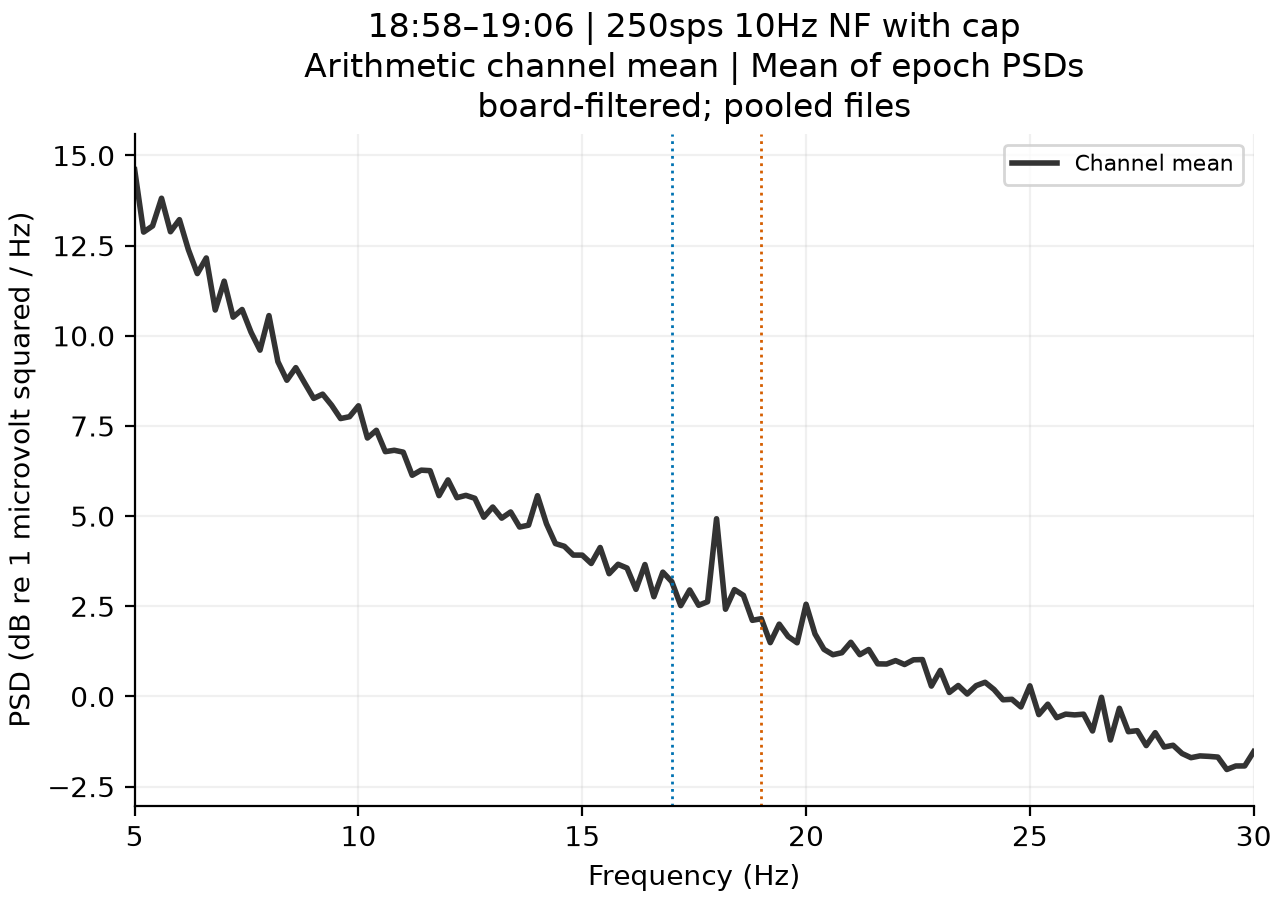
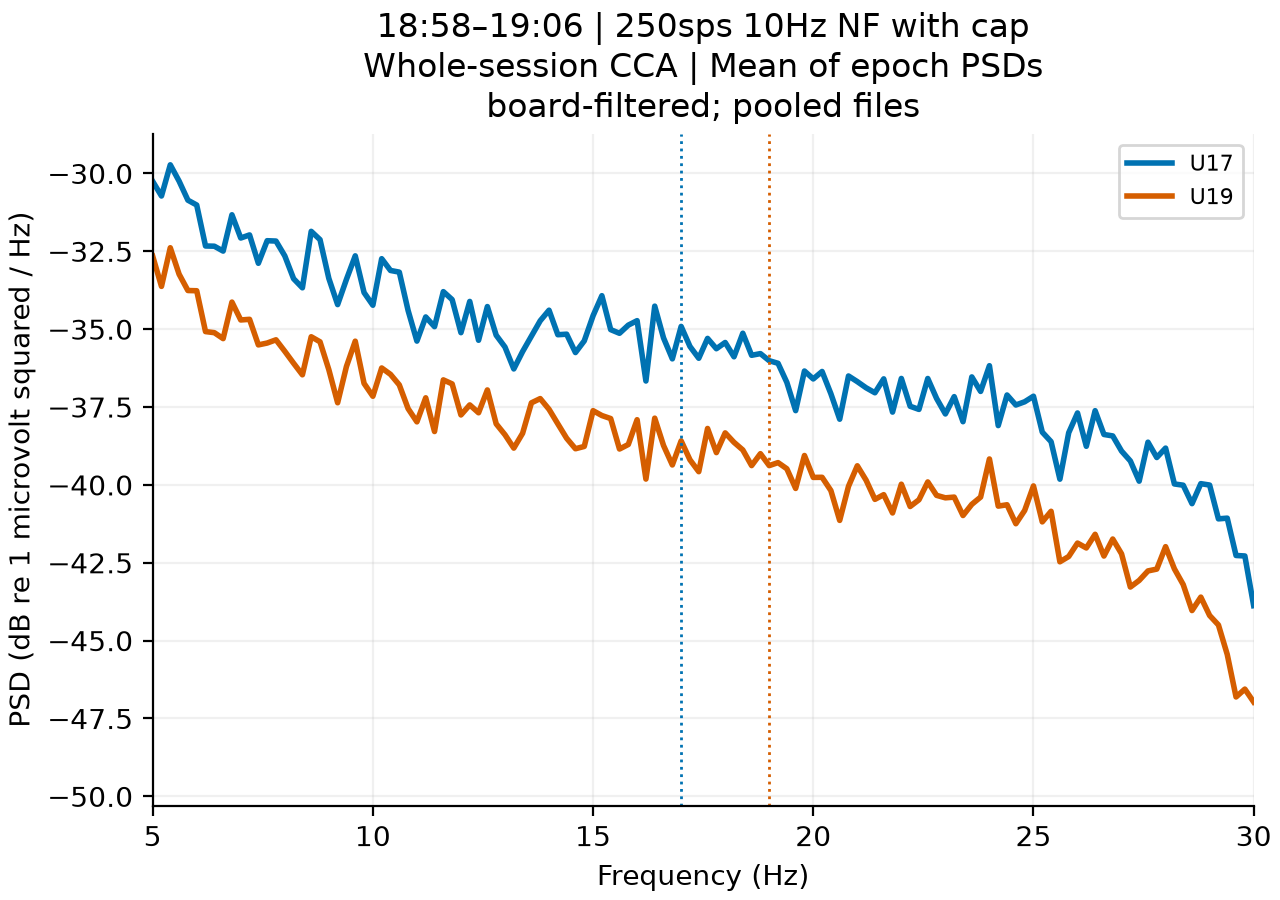
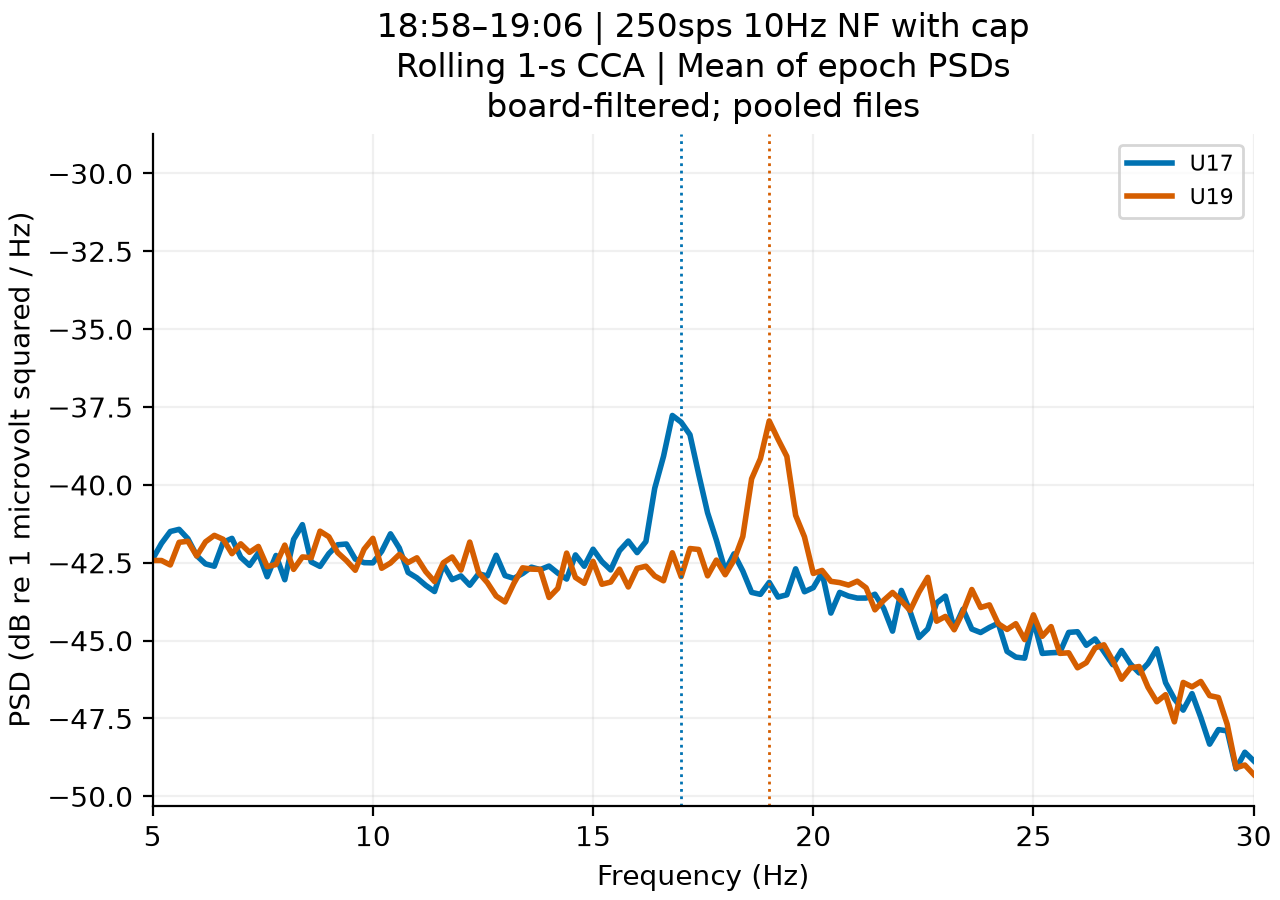
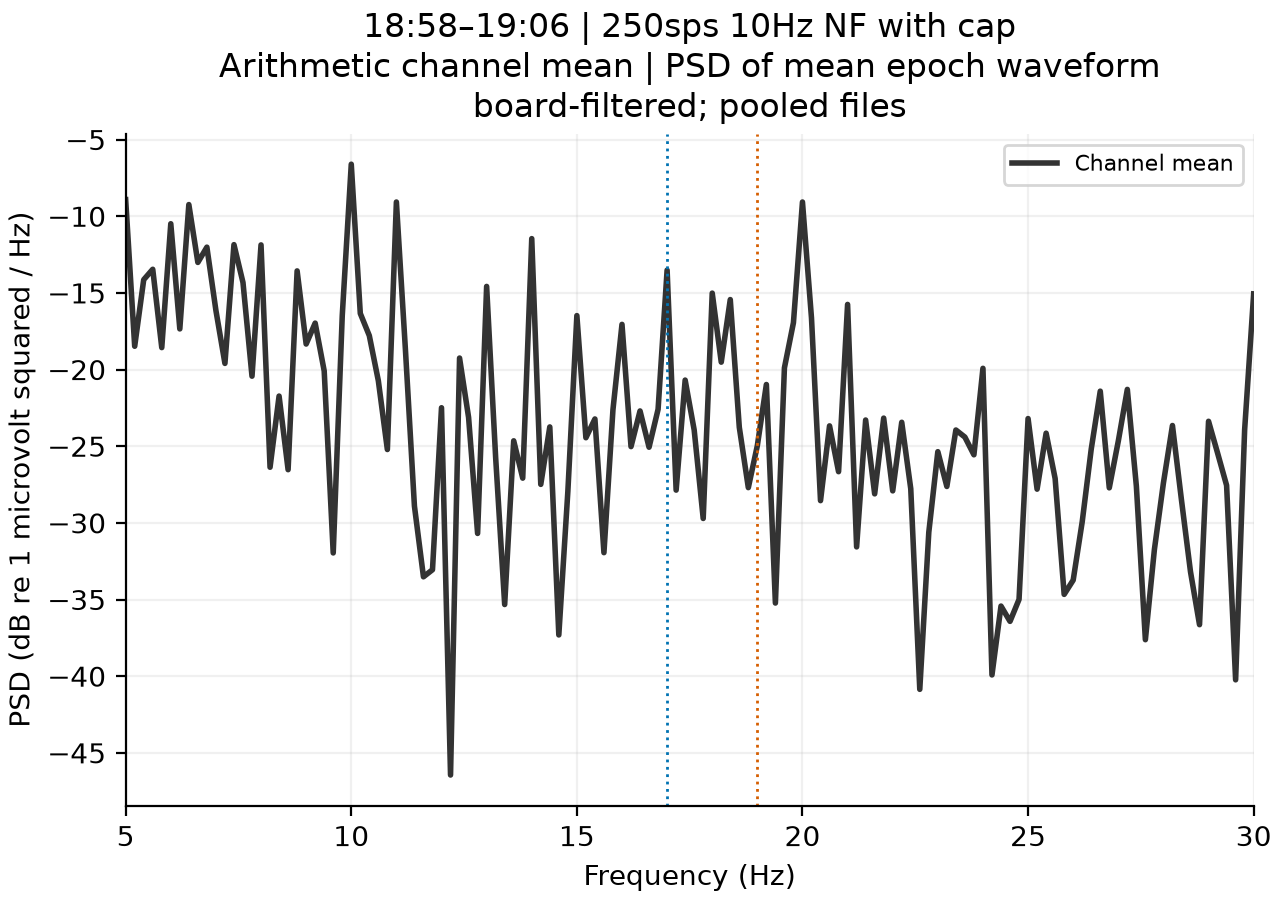
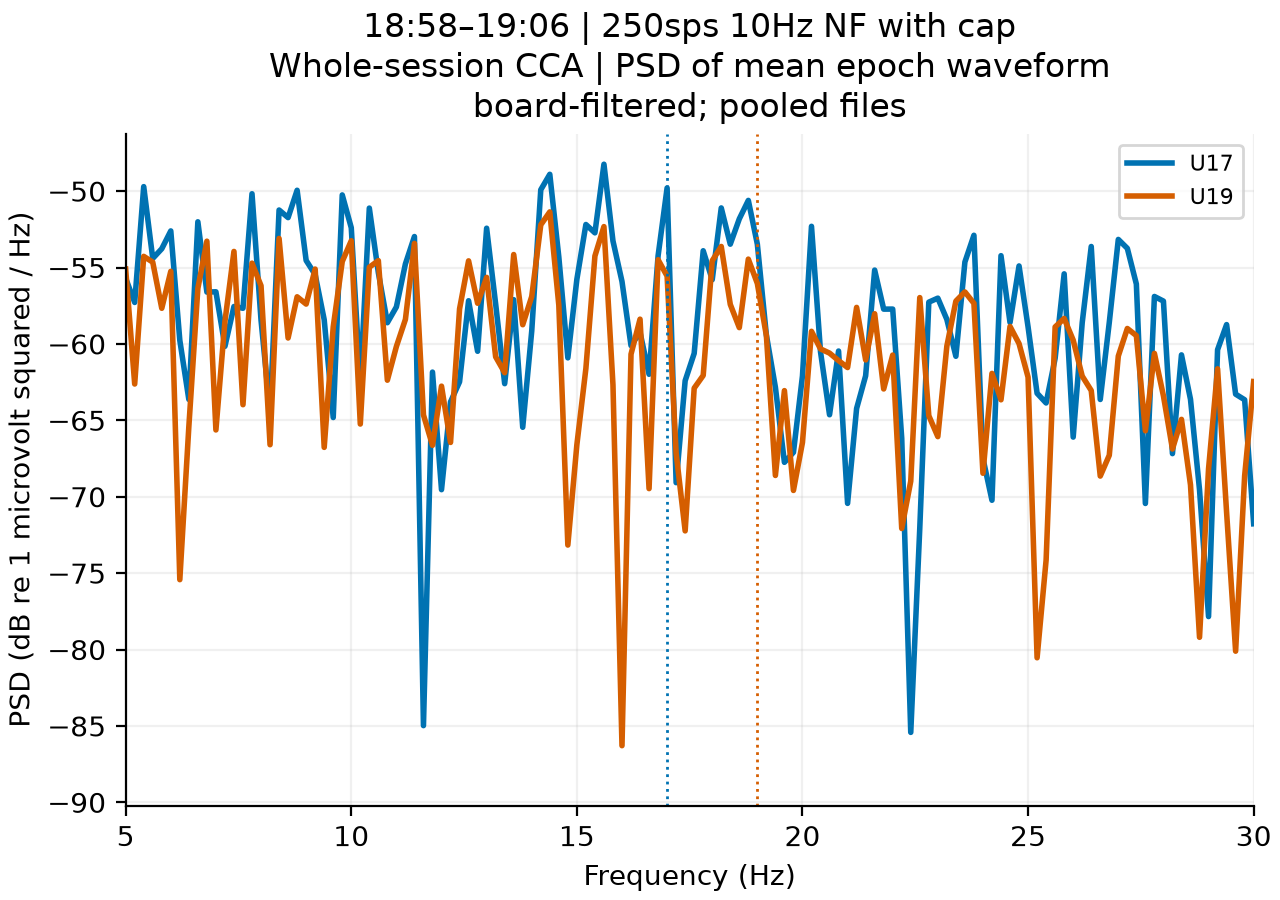
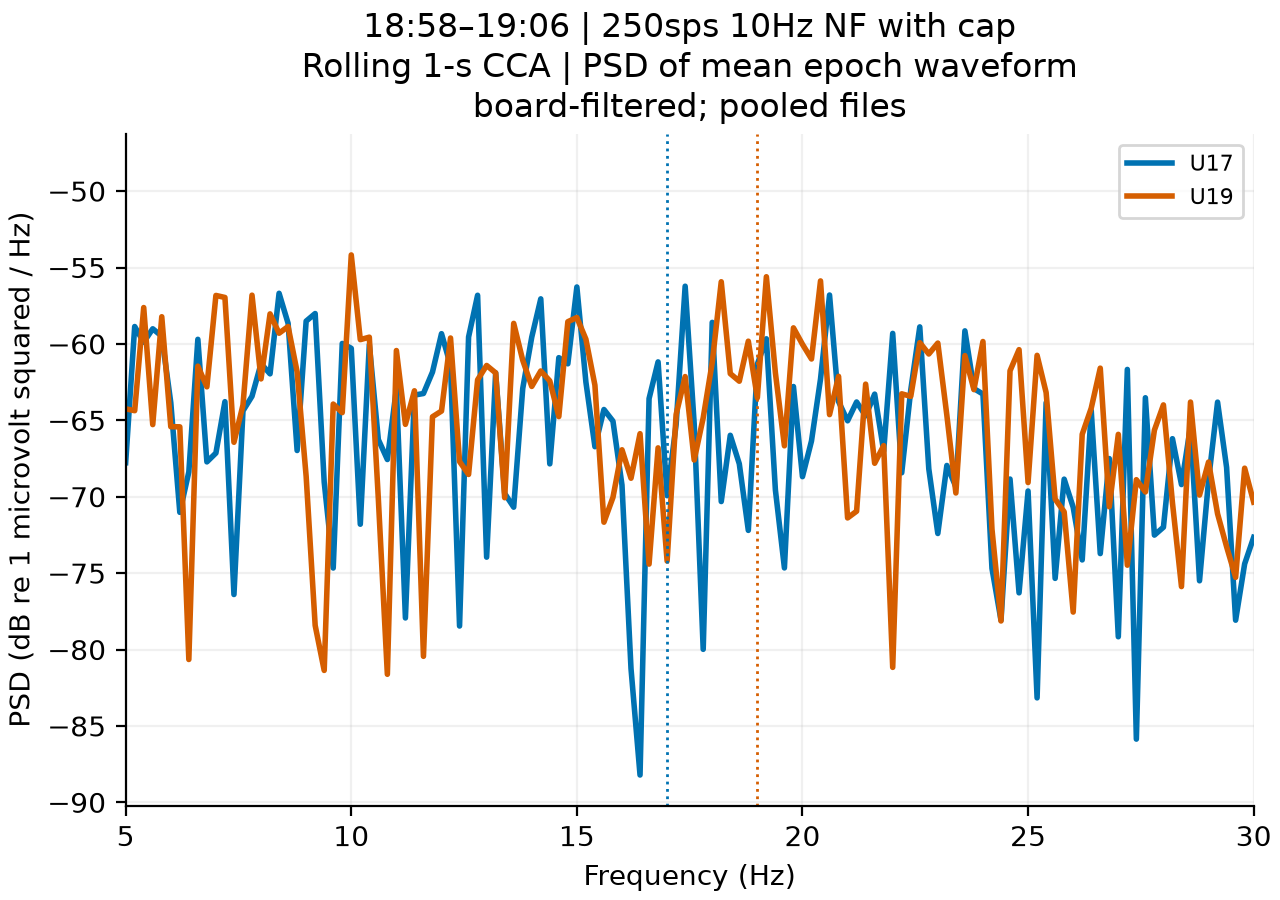

In [10]:
plot_session(records[0])

## Verify gap handling, projections, spectra, and exports

Checks confirm source byte order, source ordering, gap counts, no rolling fit
across a gap, full fixed-fit coverage, exact epoch membership, and all seven
PNG/SVG exports. The HTML report links to the saved figures.


In [11]:
import struct
rec = records[0]
assert len(records) == 1 and len(SOURCE_IDS) == 3 and len(plot_exports) == 7
assert len(seq) == 124217 and seq[-1]-seq[0]+1 == 130869
assert len(breaks) == 3 and int(gap_audit.missing_samples.sum()) == 6652
assert [b-a for a,b in segments] == [4293,3,20766,99155]
assert source_audit.loc[source_audit.file.eq(SOURCE_IDS[0]),'count_difference'].iloc[0] == -2
assert np.isfinite(rec['fixed_u']).all()
assert int(np.isnan(rec['refitted_u'][:,0]).sum()) == 3
for update in rec['update_fits']:
    a,b = rec['segments'][update['span']-1]
    assert a <= update['start'] < update['stop'] <= b
    assert np.all(np.diff(seq[update['start']:update['stop']]) == 1)
    reconstructed = np.column_stack([(rec['x'][update['lo']:update['hi']]-fit['x_mean']) @ fit['w']
        for fit in update['fits']])
    assert np.allclose(rec['refitted_u'][update['lo']:update['hi']],reconstructed)
for summary in [rec['channel_summary'],*rec['summaries'].values()]:
    assert summary['observed_samples'] == 124214 and summary['omitted_samples'] == 3
    assert summary['epochs'] == 101 and summary['complete'] == 98 and summary['partial'] == 3
    assert np.isfinite(summary['induced']).all() and np.isfinite(summary['evoked']).all()
    assert np.isclose(np.diff(summary['f']),FS/EPOCH_SAMPLES).all()
    assert np.allclose(summary['induced'],finite_mean(summary['epoch_power'],axis=0))
    assert np.allclose(summary['evoked'],nan_epoch_psd(summary['mean_epoch'],FS,EPOCH_SAMPLES)[1])
assert len({row['png'] for row in plot_exports}) == 7
assert all((EXPORT_ROOT / row[ext]).is_file() for row in plot_exports for ext in ('png','svg'))
manifest = pd.DataFrame(plot_exports)
manifest.to_csv(EXPORT_ROOT / 'plot_manifest.csv',index=False)
manifest.to_csv(rec['export_dir'] / 'plot_manifest.csv',index=False)
report = ['<!doctype html><html><head><meta charset="utf-8"><title>18:58–19:06 pooled cap EEG</title>',
    '<style>body{font-family:system-ui;max-width:1500px;margin:32px auto;padding:0 24px}img{max-width:100%}td{vertical-align:top;padding:10px}table.plots{table-layout:fixed;width:100%}table.plots td{width:33.3%}p{line-height:1.45}</style></head><body>',
    '<h1>With cap EEG: 18:58:00–19:06:47 pooled session</h1>',
    '<p>Three files, one analysis group. Three sequence gaps total 6,652 missing samples. '
    'No gap is interpolated or included in a rolling CCA fit or FFT. '
    'C9–C16 were recorded; C17–C24 were not. Five-second epochs, DPSS NW=1/K=1. '
    'Three observed samples in an isolated fragment are omitted from PSD only.</p>',
    source_audit.to_html(index=False),gap_audit.to_html(index=False)]
def card(row):
    return (f'<img src="{html.escape(row["png"])}" alt="{html.escape(row["title"])}">'
        f'<p>{html.escape(row["caption"])}</p><a href="{html.escape(row["svg"])}">SVG</a>')
report.append(card(next(p for p in plot_exports if p['view']=='per_channel')))
report.append('<table class="plots"><tr><th>Channel mean</th><th>Whole-session CCA</th><th>Rolling CCA</th></tr>')
for order in ('spectrum_first','waveform_first'):
    report.append('<tr>'+''.join('<td>'+card(next(p for p in plot_exports if p['method']==method and p['order']==order))+'</td>'
        for method in ('channel_mean','whole_session_cca','rolling_cca'))+'</tr>')
report.append('</table></body></html>')
(EXPORT_ROOT / 'index.html').write_text('\n'.join(report),encoding='utf-8')
print('Verified one pooled session: 124217 observed samples; 6652 missing sequence positions; 3 gap events.')
print('Saved 7 PNG + 7 SVG figures, numeric spectra and source/gap/CCA audits.')
print('Report:',EXPORT_ROOT / 'index.html')
display(manifest[['view','method','order','png']])

Verified one pooled session: 124217 observed samples; 6652 missing sequence positions; 3 gap events.
Saved 7 PNG + 7 SVG figures, numeric spectra and source/gap/CCA audits.
Report: C:\Users\Kalyanbrata\Documents\Android\Analysis\plots\cca_02_11_cap_1858_1906_5s_epoch_plots\index.html


,view,method,order,png
0,per_channel,independent_channels,spectrum_first,eeg_20261102_185800_to_190647/per_channel_mean...
1,channel_mean,channel_mean,spectrum_first,eeg_20261102_185800_to_190647/channels_9_10_11...
2,cca,whole_session_cca,spectrum_first,eeg_20261102_185800_to_190647/channels_9_10_11...
3,cca,rolling_cca,spectrum_first,eeg_20261102_185800_to_190647/channels_9_10_11...
4,channel_mean,channel_mean,waveform_first,eeg_20261102_185800_to_190647/channels_9_10_11...
5,cca,whole_session_cca,waveform_first,eeg_20261102_185800_to_190647/channels_9_10_11...
6,cca,rolling_cca,waveform_first,eeg_20261102_185800_to_190647/channels_9_10_11...
